# LSTM SOC Estimation - Panasonic NCR18650PF @ 25°C (Kaggle)

Comparaison finale prévue avec l'EKF sur le fichier **Cycle_1** (25°C).


## 1. Imports

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import StandardScaler

print("TF version:", tf.__version__)

TF version: 2.20.0


## 2. Chargement des données (Kaggle)

Sur Kaggle, pas besoin d'upload manuel ni de montage de Drive : tu ajoutes tes
fichiers `.mat` comme **dataset Kaggle**, et ils apparaissent automatiquement
dans `/kaggle/input/<nom-du-dataset>/`.

**Comment ajouter tes fichiers si ce n'est pas déjà fait :**
1. Dans la barre latérale droite du notebook Kaggle → **Add Input**
2. **Upload → New Dataset** → glisse tes fichiers `.mat` (tous les cycles 25°C)
3. Donne un nom au dataset (ex. `panasonic-25degc`) → **Create**
4. Le dataset est monté automatiquement sous `/kaggle/input/panasonic-25degc/`

La cellule ci-dessous liste tout ce qui est disponible sous `/kaggle/input/`
pour que tu puisses vérifier les chemins exacts avant de continuer.

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input/datasets/ramidridi/panosonic'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

## 3. Fonction de lecture d'un fichier .mat

In [3]:
def load_mat(path):
    """Charge un fichier .mat du dataset Panasonic (structure 'meas')."""
    d = sio.loadmat(path)
    m = d['meas'][0, 0]
    data = {}
    for name in m.dtype.names:
        arr = np.array(m[name]).squeeze()
        data[name] = arr
    return data

## 4. Calcul du SOC de référence (coulomb counting)

In [4]:
def compute_soc(data, capacity_Ah, soc_init=100.0):
    """
    SOC(t) = soc_init - (Ah_cumulé / capacité_nominale) * 100
    Le champ 'Ah' du dataset est déjà l'intégrale cumulée du courant
    (négatif en décharge), donc on l'utilise directement.
    """
    ah = data['Ah']
    soc = soc_init + (ah / capacity_Ah) * 100.0
    soc = np.clip(soc, 0, 100)
    return soc

# Capacité nominale à 25°C.
# -> Idéalement remplace cette valeur par celle mesurée sur ton test C20/1C
#    (dossier "C20 OCV and 1C discharge tests_start/end").
# Valeur constructeur NCR18650PF ≈ 2.9 Ah (à ajuster avec ta mesure réelle).
CAPACITY_25C = 2.9  # [Ah] <-- À AJUSTER avec ta vraie mesure

## 5. Construction des features + target pour un cycle

In [5]:
def build_features(data, soc):
    V = data['Voltage']
    I = data['Current']
    T = data['Battery_Temp_degC']
    X = np.stack([V, I, T], axis=1)   # (N, 3)
    y = soc                            # (N,)
    return X, y

## 6. Chargement des cycles (adapte le nom du dataset Kaggle et les fichiers)

**Test = Cycle_1** : c'est le fichier sur lequel l'EKF a déjà été évalué,
donc on garde EXACTEMENT le même fichier pour que la comparaison
LSTM vs EKF soit faite sur les mêmes données (même conditions, même bruit).

**Validation = HWFTb** : un fichier entier mis de côté (jamais utilisé pour
l'entraînement), pour surveiller la généralisation pendant l'entraînement.

**Train** = tous les autres cycles/profils disponibles à 25°C (Cycle_1 et
HWFTb exclus).

⚠️ Remplace `DATASET_DIR` ci-dessous par le chemin exact affiché à l'étape 2
(ex. `/kaggle/input/datasets/ramidridi/panosonic`).

In [6]:
DATASET_DIR = "/kaggle/input/datasets/ramidrid/panasonic"  # <-- chemin exact confirmé via la Cellule 2

train_files = [
    f"{DATASET_DIR}/03-18-17_02.17 25degC_Cycle_1_Pan18650PF.mat",
    f"{DATASET_DIR}/03-19-17_03.25 25degC_Cycle_2_Pan18650PF.mat",
    f"{DATASET_DIR}/03-19-17_09.07 25degC_Cycle_3_Pan18650PF.mat",
    f"{DATASET_DIR}/03-19-17_14.31 25degC_Cycle_4_Pan18650PF.mat",
    f"{DATASET_DIR}/03-20-17_05.56 25degC_HWFTa_Pan18650PF.mat",
    f"{DATASET_DIR}/03-21-17_00.29 25degC_UDDS_Pan18650PF.mat",
    f"{DATASET_DIR}/03-21-17_09.38 25degC_LA92_Pan18650PF.mat",
]
val_file = f"{DATASET_DIR}/03-20-17_19.27 25degC_HWFTb_Pan18650PF.mat"   # fichier réservé validation
test_file = f"{DATASET_DIR}/03-20-17_01.43 25degC_US06_Pan18650PF.mat"  # même fichier que ton EKF

X_train_list, y_train_list = [], []
for f in train_files:
    data = load_mat(f)
    soc = compute_soc(data, CAPACITY_25C)
    X, y = build_features(data, soc)
    X_train_list.append(X)
    y_train_list.append(y)

data_val = load_mat(val_file)
soc_val_true = compute_soc(data_val, CAPACITY_25C)
X_val, y_val = build_features(data_val, soc_val_true)

data_test = load_mat(test_file)
soc_test_true = compute_soc(data_test, CAPACITY_25C)
X_test, y_test = build_features(data_test, soc_test_true)

## 6bis. Visualisation des données brutes (avant tout entraînement)

Avant d'entraîner quoi que ce soit, on regarde à quoi ressemblent réellement
les signaux Voltage / Current / Temperature / SOC pour le fichier de test et
un fichier d'entraînement — utile pour repérer les phases de repos (courant
quasi nul), les zones bruitées, ou toute anomalie avant de se lancer dans
l'entraînement (qui prend du temps).

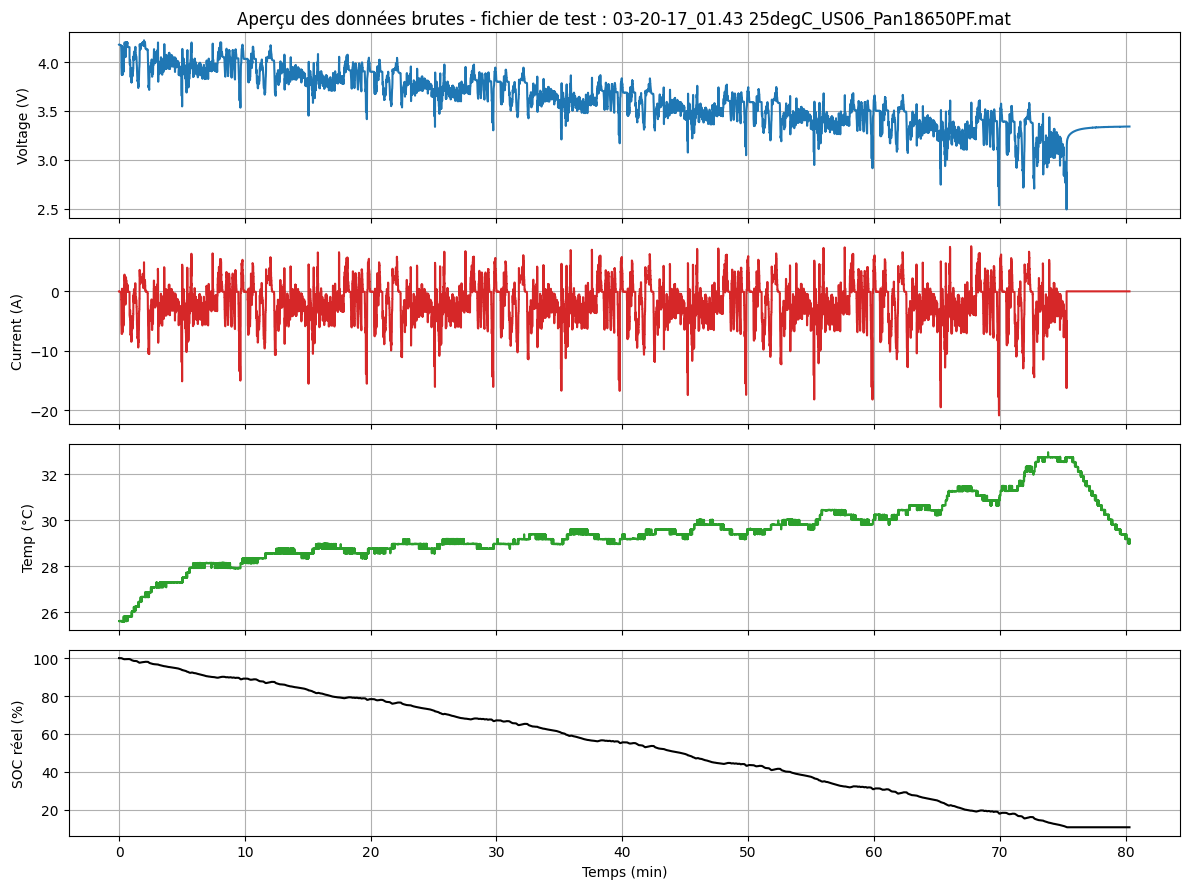

Proportion de temps à courant quasi nul (repos) dans le fichier de test : 8.4%


In [7]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

t_test_min = data_test['Time'] / 60.0

axes[0].plot(t_test_min, data_test['Voltage'], color='tab:blue')
axes[0].set_ylabel('Voltage (V)')
axes[0].set_title(f"Aperçu des données brutes - fichier de test : {test_file.split('/')[-1]}")
axes[0].grid(True)

axes[1].plot(t_test_min, data_test['Current'], color='tab:red')
axes[1].set_ylabel('Current (A)')
axes[1].grid(True)

axes[2].plot(t_test_min, data_test['Battery_Temp_degC'], color='tab:green')
axes[2].set_ylabel('Temp (°C)')
axes[2].grid(True)

axes[3].plot(t_test_min, soc_test_true, color='black')
axes[3].set_ylabel('SOC réel (%)')
axes[3].set_xlabel('Temps (min)')
axes[3].grid(True)

plt.tight_layout()
plt.show()

# Repérage rapide des zones de repos (courant quasi nul) -> utile pour comprendre
# les zones où le LSTM peut avoir plus de mal (peu représentées à l'entraînement)
idle_mask = np.abs(data_test['Current']) < 0.05
print(f"Proportion de temps à courant quasi nul (repos) dans le fichier de test : {idle_mask.mean()*100:.1f}%")

## 7. Normalisation (fit sur train uniquement)

On passe aussi en `float32` ici (au lieu de `float64` par défaut) pour diviser
la mémoire nécessaire par 2 — important pour l'étape suivante.

In [8]:
X_train_all = np.concatenate(X_train_list, axis=0)
scaler = StandardScaler()
scaler.fit(X_train_all)

def scale(X):
    return scaler.transform(X).astype(np.float32)

X_train_list = [scale(X) for X in X_train_list]
y_train_list = [y.astype(np.float32) for y in y_train_list]
X_val_scaled = scale(X_val)
y_val_f32 = y_val.astype(np.float32)
X_test_scaled = scale(X_test)
y_test_f32 = y_test.astype(np.float32)

del X_train_all  # libère la mémoire, on n'en a plus besoin
import gc; gc.collect()

15

## 8. Création des séquences (pipeline `tf.data`, sans tout charger en RAM)

**Important — pourquoi ce changement par rapport à avant :**
Construire un immense tableau NumPy contenant toutes les fenêtres glissantes de
tous les fichiers d'entraînement peut facilement dépasser 1-2 Go de RAM (d'où le
crash du kernel). `tf.keras.utils.timeseries_dataset_from_array` génère les
fenêtres **à la demande, batch par batch**, ce qui évite ce pic mémoire.

**Pourquoi un fichier de validation dédié (et pas un split par fenêtres) :**
`tf.data` ne connaît pas toujours à l'avance le nombre exact de fenêtres
générées (cardinalité "inconnue"), ce qui peut faire planter `model.fit`
("input ran out of data"). En réservant un fichier entier pour la validation
et en calculant les `steps_per_epoch` directement depuis la taille réelle des
tableaux NumPy (qu'on connaît, eux), on évite complètement ce problème.

Le jeu de test (`Cycle_1`, un seul fichier) reste construit "à l'ancienne" avec
`make_sequences`, car un seul fichier ne pose pas de problème de mémoire.

In [9]:
SEQ_LEN = 200  # nb de pas de temps dans chaque fenêtre (~200s si 1Hz)
BATCH_SIZE = 64

def make_sequences(X, y, seq_len):
    """Utilisé uniquement pour le fichier de test (un seul fichier, RAM ok)."""
    Xs, ys = [], []
    for i in range(len(X) - seq_len):
        Xs.append(X[i:i+seq_len])
        ys.append(y[i+seq_len])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

def file_windowed_dataset(X, y, seq_len):
    """Dataset de fenêtres glissantes généré à la volée (pas de gros tableau en RAM)."""
    return tf.keras.utils.timeseries_dataset_from_array(
        data=X[:-seq_len],
        targets=y[seq_len:],
        sequence_length=seq_len,
        batch_size=1,
    ).unbatch()

# --- Dataset d'entraînement : concaténation de tous les cycles train ---
train_parts = [file_windowed_dataset(X, y, SEQ_LEN) for X, y in zip(X_train_list, y_train_list)]
train_ds = train_parts[0]
for p in train_parts[1:]:
    train_ds = train_ds.concatenate(p)

# On connaît le nombre exact de fenêtres directement depuis les tableaux NumPy
# (pas besoin de faire confiance à la cardinalité tf.data, qui peut être "inconnue")
n_train = sum(len(X) - SEQ_LEN for X in X_train_list)
n_val = len(X_val_scaled) - SEQ_LEN

steps_per_epoch = n_train // BATCH_SIZE
validation_steps = max(1, n_val // BATCH_SIZE)

# .repeat() : indispensable ici, car on donne un nombre fixe de steps_per_epoch
# à Keras ; sans repeat(), le dataset s'épuiserait avant la fin de l'epoch si
# steps_per_epoch ne tombe pas rond, et on retrouverait le même avertissement.
train_ds = train_ds.shuffle(10000).repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = file_windowed_dataset(X_val_scaled, y_val_f32, SEQ_LEN)
val_ds = val_ds.repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Test : un seul fichier -> tableau classique, pas de souci mémoire
Xte_seq, yte_seq = make_sequences(X_test_scaled, y_test_f32, SEQ_LEN)

print("n_train (fenêtres):", n_train, "| steps_per_epoch:", steps_per_epoch)
print("n_val (fenêtres)  :", n_val, "| validation_steps:", validation_steps)
print("Test shape :", Xte_seq.shape, yte_seq.shape)

I0000 00:00:1786157400.531408      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786157400.534502      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


n_train (fenêtres): 883829 | steps_per_epoch: 13809
n_val (fenêtres)  : 75611 | validation_steps: 1181
Test shape : (47861, 200, 3) (47861,)


## 8bis. Reprise robuste des checkpoints (survit à un "Save & Run All")

**Le piège Kaggle :** `/kaggle/working` n'est conservé que pendant la session interactive en cours. Dès que tu cliques **Save & Run All** (indispensable pour un entraînement long en arrière-plan), Kaggle repart d'un conteneur **vide** : la logique "si `last_epoch.keras` existe -> reprise" ne trouve plus rien, même si tu avais déjà entraîné 30 epochs la veille.

**La solution :** après un run, tu télécharges le contenu de `/kaggle/working/checkpoints/` (onglet **Output**) et tu le réuploades comme **dataset Kaggle** (ex. `soc-checkpoints`) que tu ajoutes en input du notebook. La cellule ci-dessous copie automatiquement ce dataset vers `/kaggle/working/checkpoints/` **au tout début du run**, si il est présent — sinon elle ne fait rien et l'entraînement part de zéro comme avant.


In [10]:
import shutil

# <-- Mets ici le nom exact du dataset Kaggle contenant tes checkpoints d'un run
#     précédent (dossier /kaggle/input/<CHECKPOINT_DATASET_NAME>/checkpoints/...).
#     Laisse à None si c'est ton tout premier run (rien à restaurer).
CHECKPOINT_DATASET_NAME = None  # ex. "soc-checkpoints"

CHECKPOINT_ROOT = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_ROOT, exist_ok=True)

def restore_checkpoints_if_available():
    """Copie les checkpoints d'un run précédent (fournis en dataset Kaggle)
    vers /kaggle/working/checkpoints, pour que la logique de reprise de chaque
    modèle (LSTM/BiLSTM/XGBoost) les retrouve dès le début du script, y compris
    juste après un 'Save & Run All' qui repart d'un conteneur vide."""
    if CHECKPOINT_DATASET_NAME is None:
        print("CHECKPOINT_DATASET_NAME non défini -> pas de restauration, entraînement(s) depuis zéro si aucun checkpoint local.")
        return
    src = f"/kaggle/input/{CHECKPOINT_DATASET_NAME}/checkpoints"
    if not os.path.isdir(src):
        # essaie aussi le cas où le dataset a été uploadé sans le sous-dossier 'checkpoints'
        src = f"/kaggle/input/{CHECKPOINT_DATASET_NAME}"
    if not os.path.isdir(src):
        print(f"Aucun dossier de checkpoints trouvé sous /kaggle/input/{CHECKPOINT_DATASET_NAME}/ -> rien à restaurer.")
        return
    for name in os.listdir(src):
        s = os.path.join(src, name)
        d = os.path.join(CHECKPOINT_ROOT, name)
        if os.path.isdir(s):
            shutil.copytree(s, d, dirs_exist_ok=True)
        else:
            shutil.copy2(s, d)
    print(f"Checkpoints restaurés depuis {src} -> {CHECKPOINT_ROOT}")
    for root, _, files in os.walk(CHECKPOINT_ROOT):
        for fn in files:
            print(" -", os.path.join(root, fn))

restore_checkpoints_if_available()


CHECKPOINT_DATASET_NAME non défini -> pas de restauration, entraînement(s) depuis zéro si aucun checkpoint local.


## 9. Modèle LSTM

In [11]:
import pandas as pd

# --- Dossier de checkpoints persistant (reste disponible tant que la session Kaggle est active) ---
checkpoint_dir = "/kaggle/working/checkpoints/lstm"
os.makedirs(checkpoint_dir, exist_ok=True)

last_ckpt_path = os.path.join(checkpoint_dir, "last_epoch.keras")   # écrasé à CHAQUE epoch -> point de reprise
best_ckpt_path = os.path.join(checkpoint_dir, "best_model.keras")   # meilleur modèle (val_loss la plus basse)
log_path       = os.path.join(checkpoint_dir, "training_log.csv")   # historique cumulé entre les reprises

# --- Reprise automatique si un entraînement précédent a été coupé ---
if os.path.exists(last_ckpt_path):
    print(f"Checkpoint trouvé -> reprise depuis {last_ckpt_path}")
    model = tf.keras.models.load_model(last_ckpt_path)
    if os.path.exists(log_path):
        prev_log = pd.read_csv(log_path)
        initial_epoch = int(prev_log["epoch"].max()) + 1
    else:
        initial_epoch = 0
    print(f"Reprise à partir de l'epoch {initial_epoch}")
else:
    print("Aucun checkpoint trouvé, entraînement depuis zéro.")
    model = Sequential([
        tf.keras.Input(shape=(SEQ_LEN, 3)),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dense(16, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    initial_epoch = 0

model.summary()

Aucun checkpoint trouvé, entraînement depuis zéro.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 200, 64)        │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 200, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,          # arrête si val_loss ne s'améliore pas depuis 8 epochs
    restore_best_weights=True,
    verbose=1
)

checkpoint_best = ModelCheckpoint(
    filepath=best_ckpt_path,
    monitor="val_loss",
    save_best_only=True,   # ne sauvegarde que si amélioration
    verbose=1
)

checkpoint_last = ModelCheckpoint(
    filepath=last_ckpt_path,
    save_best_only=False,  # écrase à CHAQUE epoch -> permet de reprendre après une coupure de connexion
    verbose=0
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

csv_logger = CSVLogger(log_path, append=True)   # append=True : garde l'historique cumulé entre les reprises

callbacks_list = [early_stop, checkpoint_best, checkpoint_last, reduce_lr, csv_logger]

## 10. Entraînement

On repart d'une session Keras propre (`clear_session`) et on entraîne sur les
`tf.data.Dataset` construits à l'étape 8. `steps_per_epoch` et
`validation_steps` sont passés explicitement (calculés depuis la taille réelle
des données) pour éviter tout avertissement/interruption liée à une
cardinalité `tf.data` indéterminée.

In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=50,
    initial_epoch=initial_epoch,   # reprend au bon epoch si un checkpoint existait déjà
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/50
13807/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 465.7180 - mae: 7.9602
Epoch 1: val_loss improved from None to 116.41458, saving model to /kaggle/working/checkpoints/lstm/best_model.keras

Epoch 1: finished saving model to /kaggle/working/checkpoints/lstm/best_model.keras
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 302s 21ms/step - loss: 88.6317 - mae: 2.1347 - val_loss: 116.4146 - val_mae: 8.1184 - learning_rate: 0.0010
Epoch 2/50
13807/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.6696 - mae: 0.5633
Epoch 2: val_loss improved from 116.41458 to 9.02759, saving model to /kaggle/working/checkpoints/lstm/best_model.keras

Epoch 2: finished saving model to /kaggle/working/checkpoints/lstm/best_model.keras
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 296s 21ms/step - loss: 0.4379 - mae: 0.4672 - val_loss: 9.0276 - val_mae: 2.4131 - learning_rate: 0.0010
Epoch 3/50
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2659 - mae: 0.3827
Epoch 3: val_loss improved from 9.02759 to 7.30632, sa

In [14]:
import pickle

# Sauvegarde du modèle final (au cas où meilleur != dernier, best_model.keras l'a déjà)
model.save(os.path.join(checkpoint_dir, "final_model.keras"))

# Sauvegarde de l'historique d'entraînement pour tracer les courbes plus tard
with open(os.path.join(checkpoint_dir, "history.pkl"), "wb") as f:
    pickle.dump(history.history, f)

print("Modèle et historique sauvegardés dans :", checkpoint_dir)

Modèle et historique sauvegardés dans : /kaggle/working/checkpoints/lstm


## 11. Prédiction + tracé de la courbe SOC

1496/1496 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step
RMSE = 2.34 % | MAE = 1.78 %


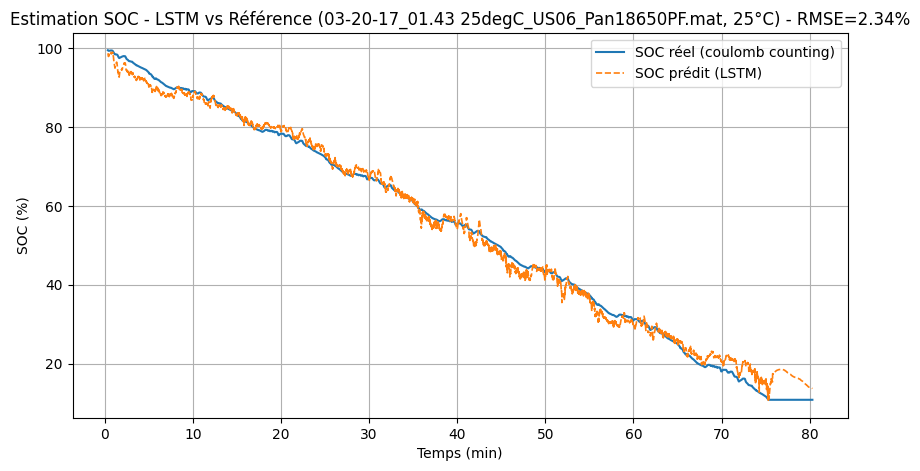

In [15]:
soc_pred = model.predict(Xte_seq).flatten()

rmse = np.sqrt(np.mean((soc_pred - yte_seq) ** 2))
mae = np.mean(np.abs(soc_pred - yte_seq))
print(f"RMSE = {rmse:.2f} % | MAE = {mae:.2f} %")

time_axis = data_test['Time'][SEQ_LEN:] / 60.0  # en minutes
test_cycle_name = test_file.split('/')[-1]  # nom du fichier de test réellement utilisé, pour un titre correct

plt.figure(figsize=(10, 5))
plt.plot(time_axis, yte_seq, label='SOC réel (coulomb counting)', linewidth=1.5)
plt.plot(time_axis, soc_pred, label='SOC prédit (LSTM)', linewidth=1.2, linestyle='--')
plt.xlabel('Temps (min)')
plt.ylabel('SOC (%)')
plt.title(f'Estimation SOC - LSTM vs Référence ({test_cycle_name}, 25°C) - RMSE={rmse:.2f}%')
plt.legend()
plt.grid(True)
plt.show()

## 12. Courbes d'apprentissage (optionnel)

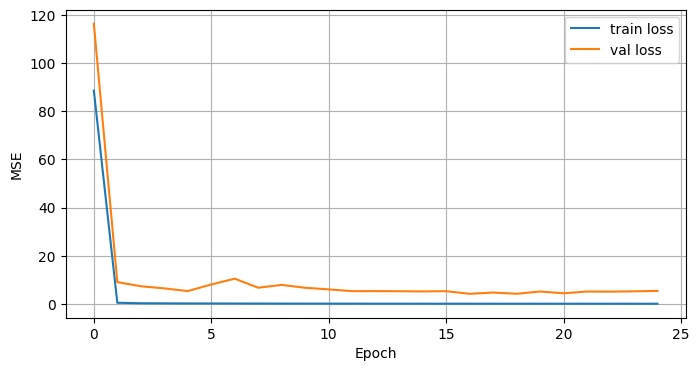

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
print(time_axis[:5])

[0.3335166  0.33501662 0.3367666  0.3383833  0.34009991]


Colonnes disponibles dans le CSV : ['Time', 'SOC_EKF']
SOC_EKF brut : min = 0.101924440014274 | max = 0.993688391543944
--> Valeurs détectées en fraction (0-1) : conversion automatique en %
Plage temps LSTM (s): 20.010995864868164 -> 4818.869999796152
Plage temps EKF CSV (s): 0.0 -> 12022.9
LSTM : RMSE = 2.34 % | MAE = 1.78 %
EKF  : RMSE = 0.86 % | MAE = 0.70 %


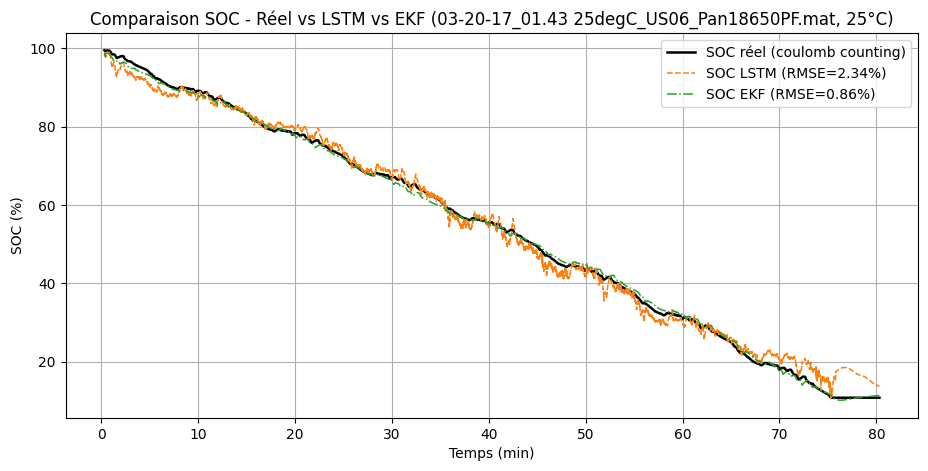

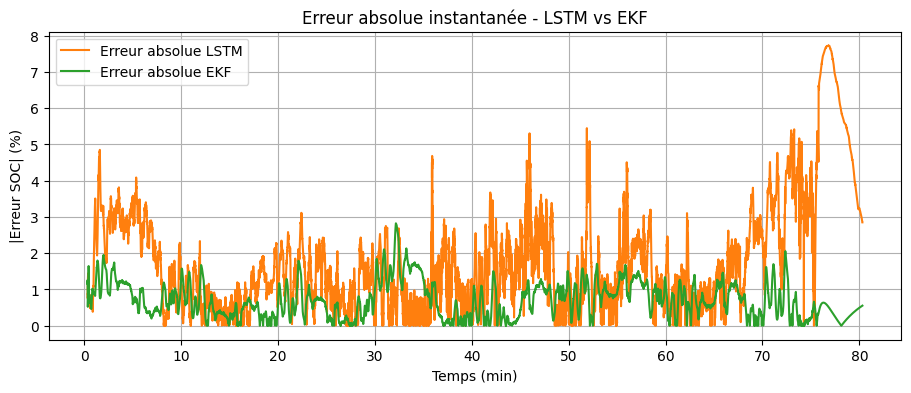

In [18]:
import pandas as pd
from scipy.interpolate import interp1d
DATASET_DIR = "/kaggle/input/datasets/ramidrid/panasonic"
EKF_CSV_PATH = f"{DATASET_DIR}/SOC.csv"  # <-- vérifie que ce chemin correspond à celui affiché par ta Cellule 2

ekf_df = pd.read_csv(EKF_CSV_PATH)
print("Colonnes disponibles dans le CSV :", list(ekf_df.columns))

time_ekf = ekf_df["Time"].values        # secondes
soc_ekf = ekf_df["SOC_EKF"].values      # % attendu, mais on vérifie ci-dessous

# --- Diagnostic + correction automatique d'échelle ---
# Si le SOC exporté depuis Simulink est en fraction (0-1) au lieu de % (0-100),
# la comparaison directe avec un SOC réel en % écrase la courbe EKF près de 0.
print("SOC_EKF brut : min =", soc_ekf.min(), "| max =", soc_ekf.max())
if soc_ekf.max() <= 1.5:
    print("--> Valeurs détectées en fraction (0-1) : conversion automatique en %")
    soc_ekf = soc_ekf * 100.0

# time_axis (LSTM/réel) est en minutes, calculé à la Cellule 11 -> on repasse en secondes pour aligner
time_axis_sec = time_axis * 60.0
print("Plage temps LSTM (s):", time_axis_sec.min(), "->", time_axis_sec.max())
print("Plage temps EKF CSV (s):", time_ekf.min(), "->", time_ekf.max())

# Interpolation de l'EKF sur les mêmes instants que le LSTM (au cas où les pas de temps diffèrent)
interp_ekf = interp1d(time_ekf, soc_ekf, bounds_error=False, fill_value="extrapolate")
soc_ekf_aligned = interp_ekf(time_axis_sec)

rmse_ekf = np.sqrt(np.mean((soc_ekf_aligned - yte_seq) ** 2))
mae_ekf = np.mean(np.abs(soc_ekf_aligned - yte_seq))

print(f"LSTM : RMSE = {rmse:.2f} % | MAE = {mae:.2f} %")
print(f"EKF  : RMSE = {rmse_ekf:.2f} % | MAE = {mae_ekf:.2f} %")

plt.figure(figsize=(11, 5))
plt.plot(time_axis, yte_seq, label='SOC réel (coulomb counting)', linewidth=1.8, color='black')
plt.plot(time_axis, soc_pred, label=f'SOC LSTM (RMSE={rmse:.2f}%)', linewidth=1.1, linestyle='--', color='tab:orange')
plt.plot(time_axis, soc_ekf_aligned, label=f'SOC EKF (RMSE={rmse_ekf:.2f}%)', linewidth=1.1, linestyle='-.', color='tab:green')
plt.xlabel('Temps (min)')
plt.ylabel('SOC (%)')
plt.title(f'Comparaison SOC - Réel vs LSTM vs EKF ({test_cycle_name}, 25°C)')
plt.legend()
plt.grid(True)
plt.show()

# Erreur absolue instantanée des deux méthodes, pour repérer où chacune diverge
plt.figure(figsize=(11, 4))
plt.plot(time_axis, np.abs(soc_pred - yte_seq), label='Erreur absolue LSTM', color='tab:orange')
plt.plot(time_axis, np.abs(soc_ekf_aligned - yte_seq), label='Erreur absolue EKF', color='tab:green')
plt.xlabel('Temps (min)')
plt.ylabel('|Erreur SOC| (%)')
plt.title('Erreur absolue instantanée - LSTM vs EKF')
plt.legend()
plt.grid(True)
plt.show()

---
# Partie 2 — Comparaison LSTM vs BiLSTM vs XGBoost

On garde le LSTM déjà entraîné (`model`, `soc_pred`, `rmse`, `mae`) et on
ajoute deux nouvelles méthodes sur les mêmes données (train/val/test
identiques, même fichier de test `Cycle_1`), pour une comparaison équitable.

## 14. Modèle BiLSTM

Même pipeline `tf.data` (`train_ds`, `val_ds`, `Xte_seq`) que pour le LSTM —
seule l'architecture change : les couches `LSTM` deviennent `Bidirectional(LSTM(...))`,
qui lisent la fenêtre dans les deux sens (passé→futur ET futur→passé) avant de
fusionner l'information. Utile car dans une fenêtre déjà connue (post-hoc, pas
en temps réel strict), le contexte "futur" de la fenêtre peut aider à mieux
situer la tendance SOC.

In [19]:
from tensorflow.keras.layers import Bidirectional

checkpoint_dir_bilstm = "/kaggle/working/checkpoints/bilstm"
os.makedirs(checkpoint_dir_bilstm, exist_ok=True)

last_ckpt_path_bilstm = os.path.join(checkpoint_dir_bilstm, "last_epoch.keras")
best_ckpt_path_bilstm = os.path.join(checkpoint_dir_bilstm, "best_model.keras")
log_path_bilstm       = os.path.join(checkpoint_dir_bilstm, "training_log.csv")

if os.path.exists(last_ckpt_path_bilstm):
    print(f"Checkpoint trouvé -> reprise depuis {last_ckpt_path_bilstm}")
    model_bilstm = tf.keras.models.load_model(last_ckpt_path_bilstm)
    if os.path.exists(log_path_bilstm):
        prev_log = pd.read_csv(log_path_bilstm)
        initial_epoch_bilstm = int(prev_log["epoch"].max()) + 1
    else:
        initial_epoch_bilstm = 0
    print(f"Reprise à partir de l'epoch {initial_epoch_bilstm}")
else:
    print("Aucun checkpoint trouvé, entraînement depuis zéro.")
    tf.keras.backend.clear_session()
    model_bilstm = Sequential([
        tf.keras.Input(shape=(SEQ_LEN, 3)),
        Bidirectional(LSTM(64, return_sequences=True)),
        Dropout(0.2),
        Bidirectional(LSTM(32)),
        Dense(16, activation='relu'),
        Dense(1, activation='linear')
    ])
    model_bilstm.compile(optimizer='adam', loss='mse', metrics=['mae'])
    initial_epoch_bilstm = 0

model_bilstm.summary()

Aucun checkpoint trouvé, entraînement depuis zéro.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 200, 128)       │        34,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,089 (301.13 KB)

 Trainable params: 77,089 (301.13 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
early_stop_bilstm = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

checkpoint_best_bilstm = ModelCheckpoint(
    filepath=best_ckpt_path_bilstm,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

checkpoint_last_bilstm = ModelCheckpoint(
    filepath=last_ckpt_path_bilstm,
    save_best_only=False,   # écrase à CHAQUE epoch -> permet de reprendre après une coupure
    verbose=0
)

reduce_lr_bilstm = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

csv_logger_bilstm = CSVLogger(log_path_bilstm, append=True)

callbacks_list_bilstm = [early_stop_bilstm, checkpoint_best_bilstm, checkpoint_last_bilstm,
                          reduce_lr_bilstm, csv_logger_bilstm]

In [21]:
history_bilstm = model_bilstm.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    epochs=50,
    initial_epoch=initial_epoch_bilstm,   # reprend au bon epoch si un checkpoint existait déjà
    callbacks=callbacks_list_bilstm,
    verbose=1
)

Epoch 1/50
13808/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 281.4591 - mae: 5.2913
Epoch 1: val_loss improved from None to 9.72388, saving model to /kaggle/working/checkpoints/bilstm/best_model.keras

Epoch 1: finished saving model to /kaggle/working/checkpoints/bilstm/best_model.keras
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 492s 35ms/step - loss: 48.0596 - mae: 1.4578 - val_loss: 9.7239 - val_mae: 2.5612 - learning_rate: 0.0010
Epoch 2/50
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.3199 - mae: 0.4171
Epoch 2: val_loss did not improve from 9.72388
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 480s 35ms/step - loss: 0.2806 - mae: 0.3831 - val_loss: 12.0934 - val_mae: 2.7094 - learning_rate: 0.0010
Epoch 3/50
13809/13809 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.2311 - mae: 0.3547
Epoch 3: val_loss improved from 9.72388 to 6.54501, saving model to /kaggle/working/checkpoints/bilstm/best_model.keras

Epoch 3: finished saving model to /kaggle/working/checkpoints/bilstm/best_model.keras
1380

1496/1496 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step
BiLSTM : RMSE = 3.82 % | MAE = 2.95 %


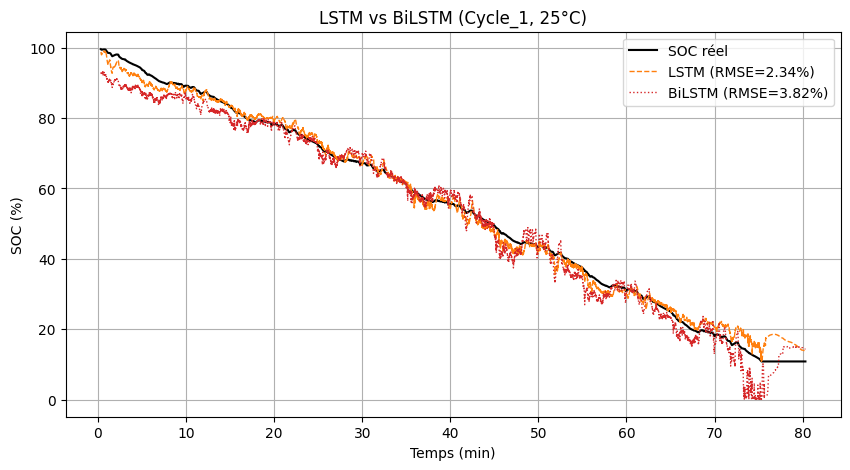

In [22]:
soc_pred_bilstm = model_bilstm.predict(Xte_seq).flatten()

rmse_bilstm = np.sqrt(np.mean((soc_pred_bilstm - yte_seq) ** 2))
mae_bilstm = np.mean(np.abs(soc_pred_bilstm - yte_seq))
print(f"BiLSTM : RMSE = {rmse_bilstm:.2f} % | MAE = {mae_bilstm:.2f} %")

plt.figure(figsize=(10, 5))
plt.plot(time_axis, yte_seq, label='SOC réel', linewidth=1.5, color='black')
plt.plot(time_axis, soc_pred, label=f'LSTM (RMSE={rmse:.2f}%)', linewidth=1.0, linestyle='--', color='tab:orange')
plt.plot(time_axis, soc_pred_bilstm, label=f'BiLSTM (RMSE={rmse_bilstm:.2f}%)', linewidth=1.0, linestyle=':', color='tab:red')
plt.xlabel('Temps (min)')
plt.ylabel('SOC (%)')
plt.title('LSTM vs BiLSTM (Cycle_1, 25°C)')
plt.legend()
plt.grid(True)
plt.show()

## 15. Modèle XGBoost (features statistiques par fenêtre)

XGBoost ne comprend pas les séquences brutes — il faut lui donner des
**features tabulaires** résumant chaque fenêtre. On calcule ces statistiques
de façon vectorisée avec `pandas.rolling()` (moyenne, écart-type, min, max,
première/dernière valeur, pente) directement sur la série temporelle brute
de chaque fichier — **sans jamais construire de tableau 3D de fenêtres**, ce
qui évite tout risque de saturation mémoire (le problème qu'on a eu avec le LSTM).

In [23]:
try:
    import xgboost as xgb
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "xgboost", "-q"])
    import xgboost as xgb

import pandas as pd

FEATURE_NAMES = ["V", "I", "T"]

def rolling_stat_features(X, seq_len):
    """
    X : array (N, 3) -> colonnes V, I, T
    Retourne un DataFrame de features statistiques glissantes, alignées de
    sorte que la ligne t correspond exactement à la même fenêtre [t-seq_len, t)
    utilisée par le LSTM pour prédire la cible y[t] (même convention que
    make_sequences : fenêtre X[i:i+seq_len] -> cible y[i+seq_len]).
    """
    df = pd.DataFrame(X, columns=FEATURE_NAMES)
    feats = {}
    for col in FEATURE_NAMES:
        roll = df[col].rolling(seq_len)
        feats[f"{col}_mean"] = roll.mean()
        feats[f"{col}_std"] = roll.std()
        feats[f"{col}_min"] = roll.min()
        feats[f"{col}_max"] = roll.max()
        feats[f"{col}_last"] = df[col]                         # dernière valeur de la fenêtre
        feats[f"{col}_first"] = df[col].shift(seq_len - 1)      # première valeur de la fenêtre
        feats[f"{col}_slope"] = (feats[f"{col}_last"] - feats[f"{col}_first"]) / seq_len

    feat_df = pd.DataFrame(feats)
    # La ligne à l'index (seq_len - 1) est la première fenêtre complète ;
    # on décale de 1 pour que featd[i] corresponde à la fenêtre X[i:i+seq_len]
    # (même convention que make_sequences -> cible y[i+seq_len])
    feat_df = feat_df.iloc[seq_len - 1: -1].reset_index(drop=True)
    return feat_df

# --- Construction des features pour train (concat de tous les fichiers), val, test ---
xgb_train_parts = []
for X, y in zip(X_train_list, y_train_list):
    f_df = rolling_stat_features(X, SEQ_LEN)
    f_df["target"] = y[SEQ_LEN:]
    xgb_train_parts.append(f_df)

xgb_train_df = pd.concat(xgb_train_parts, ignore_index=True)

xgb_val_df = rolling_stat_features(X_val_scaled, SEQ_LEN)
xgb_val_df["target"] = y_val_f32[SEQ_LEN:]

xgb_test_df = rolling_stat_features(X_test_scaled, SEQ_LEN)
xgb_test_df["target"] = y_test_f32[SEQ_LEN:]

feature_cols = [c for c in xgb_train_df.columns if c != "target"]
print("Nb features:", len(feature_cols))
print("Train:", xgb_train_df.shape, "| Val:", xgb_val_df.shape, "| Test:", xgb_test_df.shape)

Nb features: 21
Train: (883829, 22) | Val: (75611, 22) | Test: (47861, 22)


In [24]:
xgb_checkpoint_dir = "/kaggle/working/checkpoints/xgboost"
os.makedirs(xgb_checkpoint_dir, exist_ok=True)
xgb_ckpt_path = os.path.join(xgb_checkpoint_dir, "xgb_last.json")

xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    early_stopping_rounds=30,
    eval_metric="rmse",
    n_jobs=-1,
)

# --- Reprise : XGBoost n'a pas de "checkpoint par round" natif comme Keras, mais on peut
# repartir d'un modèle déjà sauvegardé avec xgb_model=... au lieu de xgb_model=None.
# NB : contrairement au LSTM, ceci ajoute de NOUVEAUX arbres sur le modèle existant plutot
# que de reprendre "au meme round" ; utile si l'entrainement precedent a ete interrompu
# mais moins critique ici car un run XGBoost est generalement bien plus rapide qu'un LSTM.
resume_from = xgb_ckpt_path if os.path.exists(xgb_ckpt_path) else None
if resume_from:
    print(f"Modèle XGBoost existant trouvé -> reprise depuis {resume_from}")
else:
    print("Aucun modèle XGBoost existant, entraînement depuis zéro.")

xgb_model.fit(
    xgb_train_df[feature_cols], xgb_train_df["target"],
    eval_set=[(xgb_val_df[feature_cols], xgb_val_df["target"])],
    xgb_model=resume_from,
    verbose=50,
)

# Sauvegarde immédiate après entraînement -> relancer cette cellule après une coupure
# reprendra depuis ce point plutôt que de tout recommencer
xgb_model.save_model(xgb_ckpt_path)
print("Modèle XGBoost sauvegardé :", xgb_ckpt_path)

Aucun modèle XGBoost existant, entraînement depuis zéro.
[0]	validation_0-rmse:26.42966
[50]	validation_0-rmse:2.48803
[100]	validation_0-rmse:1.38025
[150]	validation_0-rmse:1.28943
[200]	validation_0-rmse:1.22196
[250]	validation_0-rmse:1.15927
[300]	validation_0-rmse:1.11509
[350]	validation_0-rmse:1.08320
[400]	validation_0-rmse:1.05143
[450]	validation_0-rmse:1.02650
[499]	validation_0-rmse:1.00695
Modèle XGBoost sauvegardé : /kaggle/working/checkpoints/xgboost/xgb_last.json


XGBoost : RMSE = 1.74 % | MAE = 1.38 %


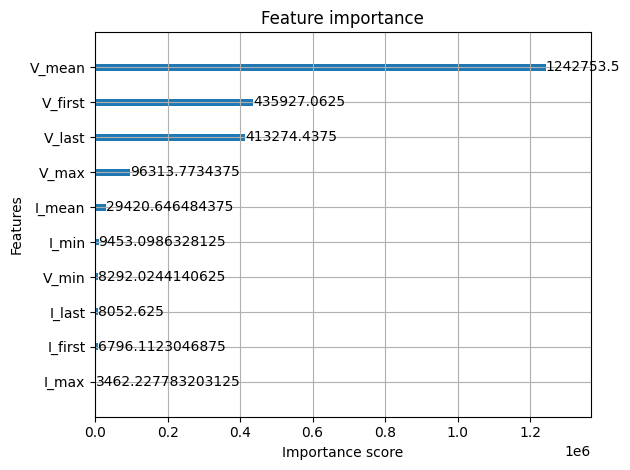

In [25]:
soc_pred_xgb = xgb_model.predict(xgb_test_df[feature_cols])
y_test_xgb = xgb_test_df["target"].values

rmse_xgb = np.sqrt(np.mean((soc_pred_xgb - y_test_xgb) ** 2))
mae_xgb = np.mean(np.abs(soc_pred_xgb - y_test_xgb))
print(f"XGBoost : RMSE = {rmse_xgb:.2f} % | MAE = {mae_xgb:.2f} %")

# Importance des features -> utile pour comprendre ce que XGBoost utilise le plus
xgb.plot_importance(xgb_model, max_num_features=10, importance_type='gain')
plt.tight_layout()
plt.show()

## 16. Comparaison finale : LSTM vs BiLSTM vs XGBoost (vs EKF si disponible)

⚠️ Si tu as déjà exécuté la cellule de superposition EKF plus haut (`soc_ekf_aligned`
disponible), elle sera incluse automatiquement. Sinon, seules les 3 méthodes IA
sont comparées.

         RMSE (%)   MAE (%)
EKF      0.858336  0.702953
XGBoost  1.737884  1.381241
LSTM     2.335451  1.783004
BiLSTM   3.819768  2.948332


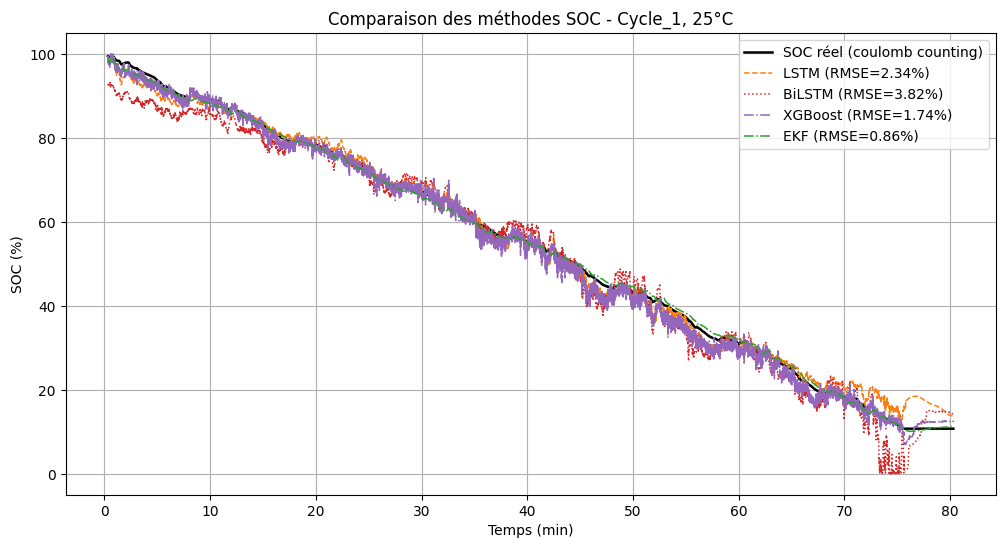

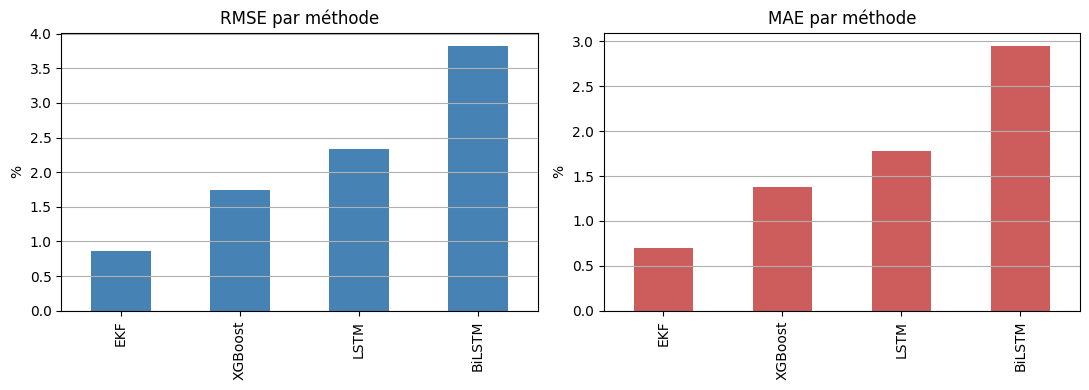

In [26]:
results = {
    "LSTM":    {"rmse": rmse,        "mae": mae,        "pred": soc_pred},
    "BiLSTM":  {"rmse": rmse_bilstm, "mae": mae_bilstm, "pred": soc_pred_bilstm},
    "XGBoost": {"rmse": rmse_xgb,    "mae": mae_xgb,    "pred": soc_pred_xgb},
}

if "soc_ekf_aligned" in globals():
    results["EKF"] = {"rmse": rmse_ekf, "mae": mae_ekf, "pred": soc_ekf_aligned}

# --- Tableau récapitulatif ---
summary_df = pd.DataFrame({
    name: {"RMSE (%)": r["rmse"], "MAE (%)": r["mae"]}
    for name, r in results.items()
}).T.sort_values("RMSE (%)")
print(summary_df)

# --- Graphique de superposition ---
colors = {"LSTM": "tab:orange", "BiLSTM": "tab:red", "XGBoost": "tab:purple", "EKF": "tab:green"}
styles = {"LSTM": "--", "BiLSTM": ":", "XGBoost": "-.", "EKF": "-."}

plt.figure(figsize=(12, 6))
plt.plot(time_axis, yte_seq, label='SOC réel (coulomb counting)', linewidth=1.8, color='black')
for name, r in results.items():
    # XGBoost peut avoir un axe temps légèrement différent (dernière ligne tronquée par shift) -> on tronque au plus court
    n = min(len(time_axis), len(r["pred"]))
    plt.plot(time_axis[:n], r["pred"][:n],
              label=f'{name} (RMSE={r["rmse"]:.2f}%)',
              linewidth=1.1, linestyle=styles.get(name, "--"), color=colors.get(name))
plt.xlabel('Temps (min)')
plt.ylabel('SOC (%)')
plt.title('Comparaison des méthodes SOC - Cycle_1, 25°C')
plt.legend()
plt.grid(True)
plt.show()

# --- Barres RMSE/MAE ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary_df["RMSE (%)"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("RMSE par méthode")
axes[0].set_ylabel("%")
axes[0].grid(True, axis="y")

summary_df["MAE (%)"].plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("MAE par méthode")
axes[1].set_ylabel("%")
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()

## 17. Sauvegarde des modèles entraînés

Sauvegarde les modèles dans `/kaggle/working/` — ce dossier est celui qui
apparaît dans l'onglet **Output** du notebook après un **Save Version**
(bouton en haut à droite), et c'est de là que tu peux les télécharger.
Ça évite de tout ré-entraîner à chaque redémarrage de session.

In [27]:
import os
os.makedirs('/kaggle/working/models', exist_ok=True)

# --- LSTM ---
model.save('/kaggle/working/models/lstm_soc_25degC.keras')

# --- BiLSTM (si déjà entraîné dans cette session) ---
if 'model_bilstm' in globals():
    model_bilstm.save('/kaggle/working/models/bilstm_soc_25degC.keras')

# --- XGBoost (si déjà entraîné dans cette session) ---
if 'xgb_model' in globals():
    xgb_model.save_model('/kaggle/working/models/xgboost_soc_25degC.json')

# --- Scaler (indispensable pour réutiliser les modèles plus tard sur de nouvelles données) ---
import joblib
joblib.dump(scaler, '/kaggle/working/models/scaler_25degC.joblib')

print("Modèles sauvegardés dans /kaggle/working/models/ :")
for f in os.listdir('/kaggle/working/models'):
    print(" -", f)

print("\nPour les récupérer : clique sur 'Save Version' (haut à droite) "
      "avec l'option 'Save & Run All', puis va dans l'onglet 'Output' "
      "de la version sauvegardée pour télécharger ces fichiers.")

Modèles sauvegardés dans /kaggle/working/models/ :
 - xgboost_soc_25degC.json
 - scaler_25degC.joblib
 - lstm_soc_25degC.keras
 - bilstm_soc_25degC.keras

Pour les récupérer : clique sur 'Save Version' (haut à droite) avec l'option 'Save & Run All', puis va dans l'onglet 'Output' de la version sauvegardée pour télécharger ces fichiers.


### Recharger les modèles plus tard (dans une nouvelle session)

À utiliser dans une future session pour éviter de tout ré-entraîner :

In [28]:
# import tensorflow as tf
# import joblib
# import xgboost as xgb
#
# model = tf.keras.models.load_model('/kaggle/working/models/lstm_soc_25degC.keras')
# model_bilstm = tf.keras.models.load_model('/kaggle/working/models/bilstm_soc_25degC.keras')
# scaler = joblib.load('/kaggle/working/models/scaler_25degC.joblib')
#
# xgb_model = xgb.XGBRegressor()
# xgb_model.load_model('/kaggle/working/models/xgboost_soc_25degC.json')

### Pour continuer l'entraînement dans un futur run (nouveau "Save & Run All")

1. Après ce run, va dans l'onglet **Output** -> télécharge tout le dossier `checkpoints/` (contient `lstm/`, `bilstm/`, `xgboost/`).
2. Crée (ou met à jour) un dataset Kaggle avec ce dossier, ex. nommé `soc-checkpoints`.
3. Ajoute ce dataset en **Add Input** sur le notebook.
4. Remonte à la cellule **8bis** et mets `CHECKPOINT_DATASET_NAME = "soc-checkpoints"` (le nom exact de ton dataset).
5. Relance **Save & Run All** : chaque modèle détectera le checkpoint restauré et reprendra à `initial_epoch` au lieu de repartir de zéro.
